In [20]:
%pip install -q otter-grader


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Case Study 12: How Much Can a Trail-Camera Network Compress Its Photos?

**DS701 — Session 15 (Mon Oct 26, 2026) — Section A1**

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tools4ds/DS701-Materials-FA26/blob/main/class_activity_notebooks/12-InClass-Exercise-SVD-A1/12-InClass-Exercise-SVD-A1.ipynb)

**Time: ~45 minutes.** Work in groups of 2-3.

Parts marked **(autograded)** are submitted to Gradescope; open-ended parts are graded
for participation. You may use AI assistance, but you must be able to explain and
justify every part of your solution when asked.

**Plan**

| Part | The nonprofit's question | Method | Grading | Time |
|---|---|---|---|---|
| 1 | What is a camera frame made of, once it is a matrix — and do the pieces add back up? | `np.linalg.svd`, shapes, rebuild | autograded | ~7 min |
| 2 | The engineers' refresher: what are singular values, and what does "rank" mean? | $\sigma_i^2 = \operatorname{eig}(A^TA)$; counting non-zero singular values | autograded | ~7 min |
| 3 | What does a frame look like at rank 1, 5, 20, 50? | Truncated SVD: rebuild the photo | autograded | ~8 min |
| 4 | What did each rank cost in fidelity, and save in bytes? | Frobenius error, energy, compression ratio | autograded | ~8 min |
| 5 | Could a cleverer compression scheme beat it? | Eckart-Young, numerically, against two rank-20 competitors | autograded | ~7 min |
| — | Report out: what you would tell the nonprofit | team memo, then pair-share | not graded | ~10 min |
| Optional | How does a real codec (JPEG) do with the same byte budget? | Pillow JPEG at a matched compression ratio | not graded | after class |

Dependencies: `numpy`, `pandas`, `matplotlib`, `scikit-learn` (and `Pillow`, which ships with `matplotlib`, for the optional section).


## Case Study Setup

You are a data scientist volunteering with an environmental nonprofit that runs a
network of wildlife **trail cameras** on the land it conserves. Each camera uploads its
photos over a **metered cellular link**, and that bandwidth is now the nonprofit's biggest
line item. They have asked you: *how far can a photo be compressed before a biologist can
no longer identify the animal in it — and when the engineers say a scheme "keeps rank
$k$", what does $k$ mean for the budget?*

The cameras' own photos are not exported yet (the field team is still collecting SD
cards), so you work on a stand-in: `china.jpg`, one of `scikit-learn`'s bundled sample
photos, converted to grayscale and cropped to a $320 \times 256$ matrix $A$ — one number
per pixel. It ships with `scikit-learn`, so nothing is downloaded. It is not a trail-camera
frame and the nonprofit never took it; it is a matrix of the right shape to work the method
out on, and the report-out asks what a real frame would change.

**What the nonprofit asked you, and where you answer it**

1. *Take one frame apart: what are the pieces, and do they add back up to the photo?* — Part 1
2. *The refresher the engineers will ask about: what are singular values, how do they
   relate to the eigenvalues they remember, and what does "rank" mean?* — Part 2
3. *What does the frame look like at rank 1, 5, 20, 50?* — Part 3
4. *Error versus bytes: what did each rank cost in fidelity, and save in transmission?* — Part 4
5. *Could a cleverer compression scheme beat the SVD at the same rank?* — Part 5

A prototype for the nonprofit's budget discussion, not a deployable codec: real image
compression (JPEG and friends) works differently, and your memo should say what this
scheme would miss.

The crop has $m > n$ to match the lecture's notation; the random toy matrix of Part 2 and
the random competitors of Part 5 are fixed by the seed below.

Run the next four cells as-is — everything below depends on them.


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_sample_image


In [22]:
# Lecture section. Only A1 runs this semester; this is kept because the build
# script reads it to name the variant directory the notebook is published in.
SECTION = "A1"
SEED = 701
rng = np.random.default_rng(SEED)


In [23]:
# Colab: fetch the autograder tests for this activity.
import os, sys, urllib.request

if "google.colab" in sys.modules:
    os.makedirs("tests", exist_ok=True)
    BASE = "https://raw.githubusercontent.com/tools4ds/DS701-Materials-FA26/main/class_activity_notebooks/12-InClass-Exercise-SVD-A1/tests/"
    for _q in ("q1", "q2", "q3", "q4", "q5"):
        urllib.request.urlretrieve(BASE + _q + ".py", "tests/" + _q + ".py")


In [24]:
# Initialize Otter
import otter
grader = otter.Notebook()

Section A1: china.jpg, A.shape = (320, 256), pixel range 0..255


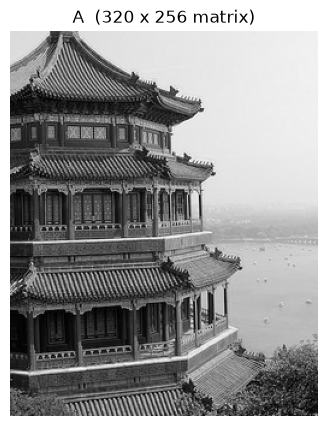

In [25]:
# This section's image: one of scikit-learn's bundled sample photos, converted to
# grayscale (mean of the RGB channels) and cropped to 320 rows x 256 columns, so m > n
# as in the lecture's notation.
IMAGE_NAME = "china.jpg"
_rgb = load_sample_image(IMAGE_NAME).astype(float)
_gray = _rgb.mean(axis=2)
_r0, _c0 = (60, 160)
A = _gray[_r0:_r0 + 320, _c0:_c0 + 256].copy()
m, n = A.shape

print(f"Section {SECTION}: {IMAGE_NAME}, A.shape = {A.shape}, pixel range {A.min():.0f}..{A.max():.0f}")
plt.figure(figsize=(4, 5))
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title(f"A  ({m} x {n} matrix)")
plt.axis("off")
plt.show()


## Part 1 (autograded): take the photo apart

**Why.** The nonprofit's first question is what a camera frame is made of once it is a
matrix, and whether the pieces add back up to the photo. The SVD is the answer: it writes
any matrix as a product of three factors, and the middle one is the importance ranking that
every later part reads. Before you compress anything, you take one frame apart and put it
back together, so you trust the pieces.

The SVD of $A \in \mathbb{R}^{m\times n}$ ($m > n$) is $A = U\Sigma V^T$ with $U$ ($m\times n$,
orthonormal columns), $\Sigma$ ($n\times n$, diagonal, $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$) and
$V$ ($n \times n$, orthonormal columns). NumPy's `np.linalg.svd(A, full_matrices=False)`
returns three things: `U`, the singular values as a **1-D array** `s`, and **`Vt`** $= V^T$
(already transposed).

**Task.**

1. Compute `U, s, Vt = np.linalg.svd(A, full_matrices=False)`.
2. Rebuild the matrix from its factors as `A_rebuilt` (hint: `np.diag(s)` turns the vector
   into $\Sigma$) and check that it equals `A` to floating-point precision.
3. Set `sigma_max` to the largest singular value as a `float`, and `rank_A` to the rank of
   `A` as an `int` (`np.linalg.matrix_rank`).


In [26]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
A_rebuilt = U @ np.diag(s) @ Vt
sigma_max = float(s[0])
rank_A = int(np.linalg.matrix_rank(A))

print("U", U.shape, " s", s.shape, " Vt", Vt.shape)
print("max |A - A_rebuilt| =", np.abs(A - A_rebuilt).max())
print("largest singular value =", round(sigma_max, 1), "  smallest =", round(float(s[-1]), 3))
print("rank(A) =", rank_A, " of at most", min(m, n))


U (320, 256)  s (256,)  Vt (256, 256)
max |A - A_rebuilt| = 1.1340262062731199e-11
largest singular value = 41476.7   smallest = 9.88
rank(A) = 256  of at most 256


In [27]:
grader.check("q1")

q1 results: All test cases passed!

## Part 2 (autograded): the refresher — singular values, eigenvalues, rank

**Why.** The nonprofit's engineers have heard that a compressed file "keeps rank $k$" and
will ask what singular values and rank are, and how they relate to the eigenvalues they
remember. This part is the refresher you need to answer them — and the warning that on a
computer "rank" is a decision about a tolerance, not a count of exact zeros.

Two facts from the linear-algebra refresher that this lecture leans on:

- $A^TA$ is symmetric and $A^TA = V\Sigma^2 V^T$, so the **eigenvalues of $A^TA$ are
  $\sigma_i^2$** (and its eigenvectors are the right singular vectors). Singular values are
  the square roots of those eigenvalues — never negative, and defined for rectangular $A$.
- The **rank** of a matrix is the number of **non-zero** singular values. On a computer
  "zero" means "tiny relative to $\sigma_1$" — floating-point arithmetic never gives exact zeros.

**Task.**

1. Compute the eigenvalues of $A^TA$ with `np.linalg.eigvalsh` (it returns them in
   *ascending* order) and store them **descending** in `eig_AtA`.
2. Set `sigma_sq_rel_diff` to $\max_i |\sigma_i^2 - \lambda_i| \,/\, \sigma_1^2$ (a `float`) and
   `sigma_sq_matches` to `True` if it is below `1e-8`.
3. `M_toy` below is a $40 \times 25$ matrix built as a product of two thin random matrices.
   Compute its singular values `s_toy` (`np.linalg.svd(..., compute_uv=False)`), set
   `rank_toy` to the number of them larger than `1e-10 * s_toy[0]` (as an `int`), and
   `n_tiny_toy` to how many are below that threshold. Compare with
   `np.linalg.matrix_rank(M_toy)`, and *look* at the tiny ones — they are not zero.


In [28]:
_rng_toy = np.random.default_rng(SEED + 1)
_r_toy = 3
M_toy = _rng_toy.normal(size=(40, _r_toy)) @ _rng_toy.normal(size=(_r_toy, 25))

eig_AtA = np.linalg.eigvalsh(A.T @ A)[::-1]                        # eigenvalues of A^T A, flipped to descending
sigma_sq_rel_diff = float(np.max(np.abs(s**2 - eig_AtA)) / s[0]**2)  # worst mismatch of sigma_i^2 vs lambda_i, relative to sigma_1^2
sigma_sq_matches = bool(sigma_sq_rel_diff < 1e-8)                  # True if they agree to floating-point precision

s_toy = np.linalg.svd(M_toy, compute_uv=False)        # singular values only, descending
tol_toy = 1e-10 * s_toy[0]                            # "zero" = tiny relative to the largest singular value
rank_toy = int(np.sum(s_toy > tol_toy))               # count the non-zero ones = numerical rank
n_tiny_toy = int(np.sum(s_toy <= tol_toy))            # the rest: round-off noise, not exact zeros


print("first three sigma^2      :", np.round(s[:3]**2, 1))
print("first three eig(A^T A)   :", np.round(eig_AtA[:3], 1))
print(f"max relative difference  : {sigma_sq_rel_diff:.2e}  -> matches: {sigma_sq_matches}")
print()
print("toy singular values      :", np.array2string(s_toy, precision=2, max_line_width=120))
print(f"rank_toy = {rank_toy} (numpy says {np.linalg.matrix_rank(M_toy)}), tiny ones: {n_tiny_toy}")


first three sigma^2      : [1.72031790e+09 6.70332746e+07 1.41628512e+07]
first three eig(A^T A)   : [1.72031790e+09 6.70332746e+07 1.41628512e+07]
max relative difference  : 1.11e-15  -> matches: True

toy singular values      : [4.41e+01 3.08e+01 2.48e+01 4.11e-15 2.90e-15 2.36e-15 1.94e-15 1.66e-15 1.45e-15 1.34e-15 1.09e-15 1.03e-15 9.55e-16
 8.75e-16 7.33e-16 6.84e-16 6.24e-16 5.82e-16 5.03e-16 4.29e-16 3.83e-16 3.38e-16 3.18e-16 1.88e-16 1.00e-16]
rank_toy = 3 (numpy says 3), tiny ones: 22


In [29]:
grader.check("q2")

q2 results: All test cases passed!

## Part 3 (autograded): rebuild the photo at rank 1, 5, 20, 50

**Why.** The question the biologists care about: what does a frame look like at rank 1, 5,
20, 50 — at which rank can you still tell what is in the picture? The truncated SVD keeps
the $k$ heaviest rank-1 layers, and this part builds it so you can look.

The truncated SVD keeps the $k$ heaviest rank-1 layers:
$$A^{(k)} = U'\Sigma'(V')^T = \sum_{i=1}^{k} \sigma_i \mathbf{u}_i \mathbf{v}_i^T,$$
where $U'$ is the first $k$ columns of $U$, $\Sigma'$ the top-left $k\times k$ block of $\Sigma$
and $(V')^T$ the first $k$ **rows** of `Vt`.

**Task.**

1. Write `rank_k_approx(U, s, Vt, k)` returning $A^{(k)}$ as an $m\times n$ array. Slice —
   do not recompute the SVD inside.
2. Build `A_k = {k: rank_k_approx(U, s, Vt, k) for k in KS}` for `KS = [1, 5, 20, 50]`.

Then run the plotting cell that follows and *look* before moving on: at which $k$ can you
first tell what the photo is?


In [30]:
KS = [1, 5, 20, 50]


def rank_k_approx(U, s, Vt, k):
    """Best rank-k approximation from a precomputed SVD: U[:, :k] diag(s[:k]) Vt[:k]."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]   # first k columns of U, top-left k x k of Sigma, first k rows of Vt

A_k = {k: rank_k_approx(U, s, Vt, k) for k in KS}  # one m x n approximation per rank in KS

for k in KS:
    print(f"k = {k:2d}: A_k shape {A_k[k].shape}, rank {np.linalg.matrix_rank(A_k[k])}")


k =  1: A_k shape (320, 256), rank 1
k =  5: A_k shape (320, 256), rank 5
k = 20: A_k shape (320, 256), rank 20
k = 50: A_k shape (320, 256), rank 50


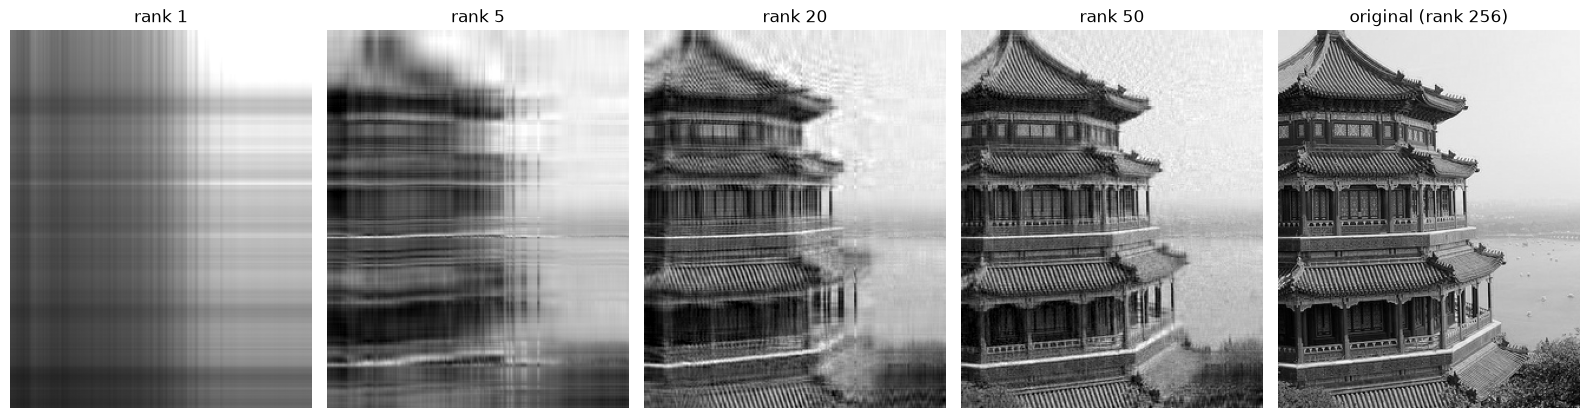

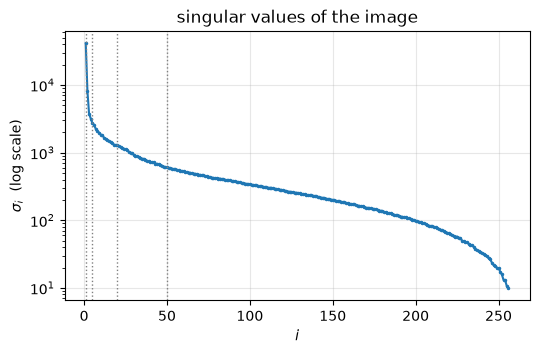

In [31]:
fig, axes = plt.subplots(1, len(KS) + 1, figsize=(3.2 * (len(KS) + 1), 4.4))
for ax, k in zip(axes, KS):
    ax.imshow(A_k[k], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"rank {k}")
    ax.axis("off")
axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title(f"original (rank {min(m, n)})")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 3.5))
plt.semilogy(np.arange(1, n + 1), s, ".-", ms=3)
for k in KS:
    plt.axvline(k, color="gray", ls=":", lw=1)
plt.xlabel("$i$")
plt.ylabel(r"$\sigma_i$  (log scale)")
plt.title("singular values of the image")
plt.grid(alpha=0.3)
plt.show()


In [32]:
grader.check("q3")

q3 results: All test cases passed!

## Part 4 (autograded): error, energy, and what you paid for it

**Why.** The nonprofit's budget question: for each rank, what did you lose in fidelity and
what did you save in bytes over the cellular link? Three numbers answer it — the Frobenius
error, the energy captured and the compression ratio — and Eckart-Young lets you read the
first one off the singular values without rebuilding anything.

Three numbers summarise a rank-$k$ approximation:

- **Frobenius error** $\lVert A - A^{(k)}\rVert_F$ — Eckart-Young says this equals
  $\sqrt{\sum_{i>k}\sigma_i^2}$, the discarded singular values;
- **energy captured** $\;\sum_{i\le k}\sigma_i^2 \,/\, \sum_i \sigma_i^2$ — the fraction of
  $\lVert A\rVert_F^2$ that survives;
- **compression ratio** — storing $U'$ ($m\times k$), the $k$ singular values and $(V')^T$
  ($k \times n$) costs $k(m+n+1)$ numbers instead of $mn$; the ratio is $\dfrac{mn}{k(m+n+1)}$.

**Task.**

1. `frob_err = {k: ||A - A_k[k]||_F}` for `k in KS`, computed **directly** with
   `np.linalg.norm` (as floats), and `frob_err_formula = {k: sqrt(sum of s[i]^2 for i >= k)}`
   from the singular values. They should agree to many digits.
2. `energy` — a length-`n` array whose entry `k-1` is the energy captured by rank $k$
   (`np.cumsum` will help), and `energy_at = {k: energy[k-1]}` for `k in KS`.
3. `k_99` — the smallest $k$ whose energy is at least 0.99, as an `int`.
4. `compression_ratio = {k: m*n / (k*(m+n+1))}` for `k in KS` (floats).


In [33]:
frob_err = {k: float(np.linalg.norm(A - A_k[k])) for k in KS}           # ||A - A_k||_F, computed directly
frob_err_formula = {k: float(np.sqrt(np.sum(s[k:]**2))) for k in KS}   # Eckart-Young: sqrt of the discarded sigma_i^2
energy = np.cumsum(s**2) / np.sum(s**2)                                # entry k-1 = energy kept by rank k
energy_at = {k: float(energy[k - 1]) for k in KS}                      # energy at the ranks we plotted
k_99 = int(np.argmax(energy >= 0.99) + 1)                              # first index reaching 99%, +1 to turn it into a rank
compression_ratio = {k: m * n / (k * (m + n + 1)) for k in KS}         # mn numbers vs k(m+n+1) for U', sigmas, V'^T

pd.DataFrame({
    "Frobenius error (direct)": frob_err,
    "Frobenius error (formula)": frob_err_formula,
    "relative error": {k: frob_err[k] / np.linalg.norm(A) for k in KS},
    "energy captured": energy_at,
    "compression ratio": compression_ratio,
}).round(4).rename_axis("k")


,Frobenius error (direct),Frobenius error (formula),relative error,energy captured,compression ratio
k,,,,,
1,13511.7550,13511.7550,0.3097,0.9041,141.9757
5,9156.4867,9156.4867,0.2099,0.9559,28.3951
20,6187.3496,6187.3496,0.1418,0.9799,7.0988
50,3904.0212,3904.0212,0.0895,0.9920,2.8395


smallest k with >= 99% energy: k_99 = 42   (compression ratio there: 3.4x)


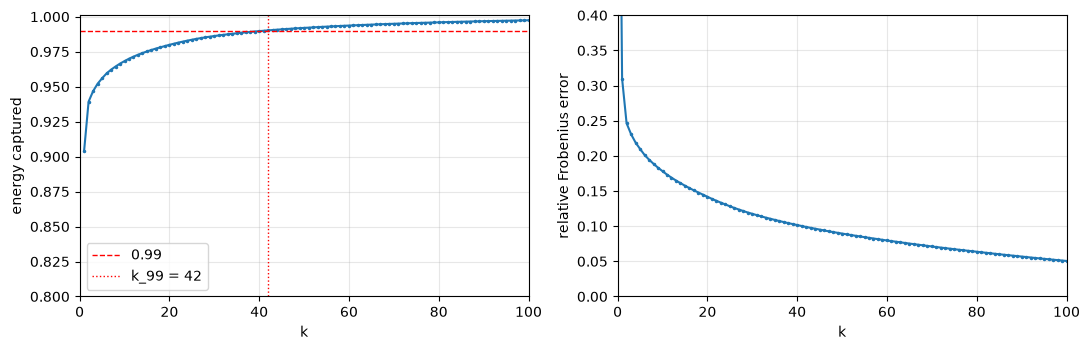

In [34]:
print(f"smallest k with >= 99% energy: k_99 = {k_99}   (compression ratio there: {m*n/(k_99*(m+n+1)):.1f}x)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(1, n + 1), energy, ".-", ms=3)
ax[0].axhline(0.99, color="red", ls="--", lw=1, label="0.99")
ax[0].axvline(k_99, color="red", ls=":", lw=1, label=f"k_99 = {k_99}")
ax[0].set_xlim(0, 100); ax[0].set_ylim(0.8, 1.001)
ax[0].set_xlabel("k"); ax[0].set_ylabel("energy captured"); ax[0].legend(); ax[0].grid(alpha=0.3)
rel = np.sqrt(np.cumsum(s[::-1]**2)[::-1]) / np.linalg.norm(A)
ax[1].plot(np.arange(0, n), rel, ".-", ms=3)
ax[1].set_xlim(0, 100); ax[1].set_ylim(0, 0.4)
ax[1].set_xlabel("k"); ax[1].set_ylabel("relative Frobenius error"); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Discuss (participation):** the nonprofit's engineers read "rank 1 captures about 90% of
the energy" off your table and ask why they should pay for any more rank than that — yet the
rank-1 frame is a smear no biologist could identify an animal in. What does the first rank-1
layer $\sigma_1\mathbf{u}_1\mathbf{v}_1^T$ actually capture in a photograph, why does the energy
fraction flatter it, and which number in your table would you show them instead? (Hint: pixel
values are all positive. What would change if you subtracted the mean pixel value from `A`
before the SVD? Next lecture does exactly that.)

*The first layer σ₁u₁v₁ᵀ mostly captures the frame's overall brightness. Because pixel values are all positive, the mean alone accounts for about 75% of ‖A‖²_F, so "90% energy" mostly measures exposure, not the edges and texture. I'd show the relative error instead (rank 1 still misses 31% of the image), or center the image first: with the mean subtracted, rank 1 keeps only 53% of the energy and reaching 99% takes k = 101 instead of 42.*


In [35]:
grader.check("q4")

q4 results: All test cases passed!

## Part 5 (autograded): Eckart-Young, numerically — beat the SVD if you can

**Why.** Sooner or later a vendor will pitch the nonprofit a "smarter" rank-20 scheme.
Before you tell them the truncated SVD is the best anyone can do at a given rank, you should
have tried to beat it yourself.

Eckart-Young says $A^{(k)}$ is the closest rank-$k$ matrix to $A$ among **all** rank-$k$
matrices. Let us try to beat it at $k = 20$ with two competitors:

- `B_random` — a random rank-20 matrix, rescaled to have the same Frobenius norm as `A`
  (built for you below): the *worst kind* of rank-20 guess;
- `B_cols` — a **sensible** rank-20 matrix built from the image itself: take 20 columns of
  `A` (indices `cols`, chosen at random) as a basis $C = $ `A[:, cols]` and replace *every*
  column of `A` by its least-squares fit onto that basis. Every column of `B_cols` lies in
  the span of 20 real image columns, so its rank is (at most) 20.

**Task.**

1. `C = A[:, cols]`; solve the least-squares problem $C X \approx A$ with
   `np.linalg.lstsq(C, A, rcond=None)[0]` and set `B_cols = C @ X`.
2. `err_random`, `err_cols`, `err_svd` — the Frobenius errors $\lVert A - B\rVert_F$ of the two
   competitors and of `A_k[20]` (floats).
3. `eckart_young_holds` — `True` if the SVD error is $\le$ both competitors' errors.
4. `cols_penalty_pct` — how much worse `B_cols` is than the SVD, in percent:
   $100\,(\text{err\_cols} - \text{err\_svd})/\text{err\_svd}$.


rank(B_cols) = 20
||A - B_random||_F =   61656.5
||A - B_cols||_F   =    8682.5   (40.3% worse than the SVD)
||A - A_k[20]||_F  =    6187.3
Eckart-Young holds: True


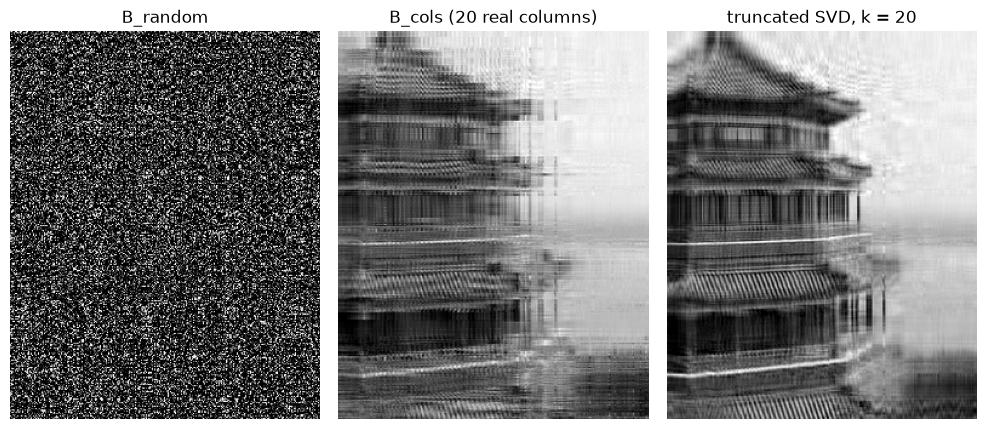

In [36]:
k_test = 20
_rng_ey = np.random.default_rng(SEED + 7)
B_random = _rng_ey.normal(size=(m, k_test)) @ _rng_ey.normal(size=(k_test, n))
B_random *= np.linalg.norm(A) / np.linalg.norm(B_random)      # same overall size as A
cols = np.sort(_rng_ey.choice(n, k_test, replace=False))       # 20 columns of A, at random

C = A[:, cols]                                              # the 20 chosen image columns as a basis
X_ls = np.linalg.lstsq(C, A, rcond=None)[0]                 # least-squares coefficients: C @ X_ls ~ A
B_cols = C @ X_ls                                           # every column of A replaced by its fit in span(C)
err_random = float(np.linalg.norm(A - B_random))            # Frobenius error of the random rank-20 guess
err_cols = float(np.linalg.norm(A - B_cols))                # Frobenius error of the column-subset scheme
err_svd = float(np.linalg.norm(A - A_k[k_test]))            # Frobenius error of the truncated SVD at k = 20
eckart_young_holds = bool(err_svd <= err_random and err_svd <= err_cols)   # SVD beats both competitors
cols_penalty_pct = 100 * (err_cols - err_svd) / err_svd    # how much worse B_cols is, in percent


print(f"rank(B_cols) = {np.linalg.matrix_rank(B_cols)}")
print(f"||A - B_random||_F = {err_random:9.1f}")
print(f"||A - B_cols||_F   = {err_cols:9.1f}   ({cols_penalty_pct:.1f}% worse than the SVD)")
print(f"||A - A_k[20]||_F  = {err_svd:9.1f}")
print("Eckart-Young holds:", eckart_young_holds)

fig, axes = plt.subplots(1, 3, figsize=(10, 4.2))
for ax, (img, title) in zip(axes, [(B_random, "B_random"), (B_cols, "B_cols (20 real columns)"), (A_k[k_test], "truncated SVD, k = 20")]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


**Discuss (participation):** suppose a vendor tells the nonprofit their scheme stores 20
*actual columns* of each frame plus fitting coefficients — "real pixels, not abstract
factors" — and that with a smarter choice of columns it will match the SVD. `B_cols` *is*
that scheme, with random columns, and it loses by 30-70%. Would searching **all** possible
20-column subsets (there are about $10^{28}$) ever let them beat the SVD? What do the first 20
columns of $U$ have that any subset of frame columns cannot?

*No. Eckart-Young says A⁽²⁰⁾ is the closest matrix to A among all rank-20 matrices, and every column-subset fit B_cols is one of those, so even the best of the ~10²⁸ subsets can at most tie the SVD (and only if its 20 columns happened to span exactly the top-20 left singular subspace, which real frame columns essentially never do). The first 20 columns of U are not tied to any actual pixels: each is an optimal orthonormal blend of all the columns, chosen so that each successive direction captures as much of the remaining ‖A‖²_F as possible, whereas real columns are redundant with each other and each carries its own local noise.*


In [37]:
grader.check("q5")

q5 results: All test cases passed!

<!-- BEGIN QUESTION -->

## Report out: what you would tell the nonprofit

Discuss as a team (~5 min), then write in the cell below. This is not graded, but staff
will ask about it at your table and in the next recap, and it is what you will share.

Write the two sentences you would put at the top of your memo to the nonprofit: the
**recommendation** — the rank you would set for the cameras, with the compression ratio and
relative error it buys (Part 4) — and the **one caveat they must hear** — the kind of photo
this scheme would fail on, and how you would find out. Then pair-share (~3 min) with
another team: did you pick the same rank? If not, whose evidence is stronger? Be ready to
share one takeaway with the class.

Worth settling as you write:

- Which number in Part 4's table is the honest measure of what a biologist loses — energy
  captured or relative error — and why?
- The frame you compressed is a stand-in. What about a real trail-camera frame — a small
  animal at night, a frame that is mostly grass, sensor noise — would make the spectrum fall
  more slowly, and what happens to your rank then?
- The photo was full rank algebraically (Part 1), and you are recommending a rank far below
  it. Say in one sentence why both are true.


_Type your answer here, replacing this text._

<!-- END QUESTION -->

## Wrap-up

Before you leave, each group should be able to answer, without notes:

1. Which factor of $A = U\Sigma V^T$ holds the importance ranking, and how do you read the
   error of a rank-$k$ approximation off it without forming $A^{(k)}$?
2. In one sentence, what does Eckart-Young promise — and what did the `B_cols` experiment
   show about "reasonable" competitors?
3. The photo is full rank algebraically, yet you told the nonprofit to keep a fraction of
   it. Which word in "low *effective* rank" does the work?

Submit the autograded parts (1-5) to Gradescope.


## Optional (not graded): compare with JPEG at the same compression ratio

**Why.** Your memo says the SVD scheme is a prototype and that "real image compression
(JPEG and friends) works differently". This section puts a number on that sentence: give
JPEG exactly the byte budget the rank-$k$ SVD gets, and compare the pictures and the errors
side by side.

**Matching the budget.** The frame stored as 8-bit pixels takes $mn$ bytes. Part 4's
compression ratio $\dfrac{mn}{k(m+n+1)}$ counts *numbers*; to turn it into bytes we assume
each of the $k(m+n+1)$ SVD numbers is also stored in **one byte**. That is generous to the
SVD — the factors are floats, and squeezing them into 8 bits would add error that the
rank-$k$ pictures above do not show. So JPEG's budget for rank $k$ is $k(m+n+1)$ bytes, and
we use the highest JPEG quality setting whose file fits in it.

Nothing to write — run the two cells and look.

In [38]:
import io
from PIL import Image

A_uint8 = np.clip(np.round(A), 0, 255).astype(np.uint8)  # the frame as 8-bit pixels: m*n bytes


def jpeg_roundtrip(img, quality):
    """Encode an 8-bit grayscale array as JPEG; return (file size in bytes, decoded image)."""
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="JPEG", quality=quality, optimize=True)
    data = buf.getvalue()
    return len(data), np.asarray(Image.open(io.BytesIO(data)), dtype=float)


def jpeg_at_budget(img, max_bytes):
    """Highest JPEG quality (1-95) whose file fits in max_bytes, or None if even quality 1 is too big."""
    best = None
    for q in range(1, 96):
        size, decoded = jpeg_roundtrip(img, q)
        if size <= max_bytes:
            best = (q, size, decoded)
    return best


A_jpeg = {}
rows = []
for k in KS:
    budget = k * (m + n + 1)
    row = {"k": k, "budget (bytes)": budget, "compression ratio": A_uint8.nbytes / budget,
           "SVD relative error": np.linalg.norm(A - A_k[k]) / np.linalg.norm(A)}
    found = jpeg_at_budget(A_uint8, budget)
    if found is not None:
        q, size, A_jpeg[k] = found
        row.update({"JPEG quality": q, "JPEG bytes": size,
                    "JPEG relative error": np.linalg.norm(A - A_jpeg[k]) / np.linalg.norm(A)})
    rows.append(row)

print(f"raw frame: {A_uint8.nbytes} bytes; smallest possible JPEG (quality 1): {jpeg_roundtrip(A_uint8, 1)[0]} bytes")
pd.DataFrame(rows).set_index("k").round(4)

raw frame: 81920 bytes; smallest possible JPEG (quality 1): 1393 bytes


,budget (bytes),compression ratio,SVD relative error,JPEG quality,JPEG bytes,JPEG relative error
k,,,,,,
1,577,141.9757,0.3097,NaN,NaN,NaN
5,2885,28.3951,0.2099,6.0,2616.0,0.1389
20,11540,7.0988,0.1418,41.0,11423.0,0.0737
50,28850,2.8395,0.0895,88.0,28325.0,0.0246


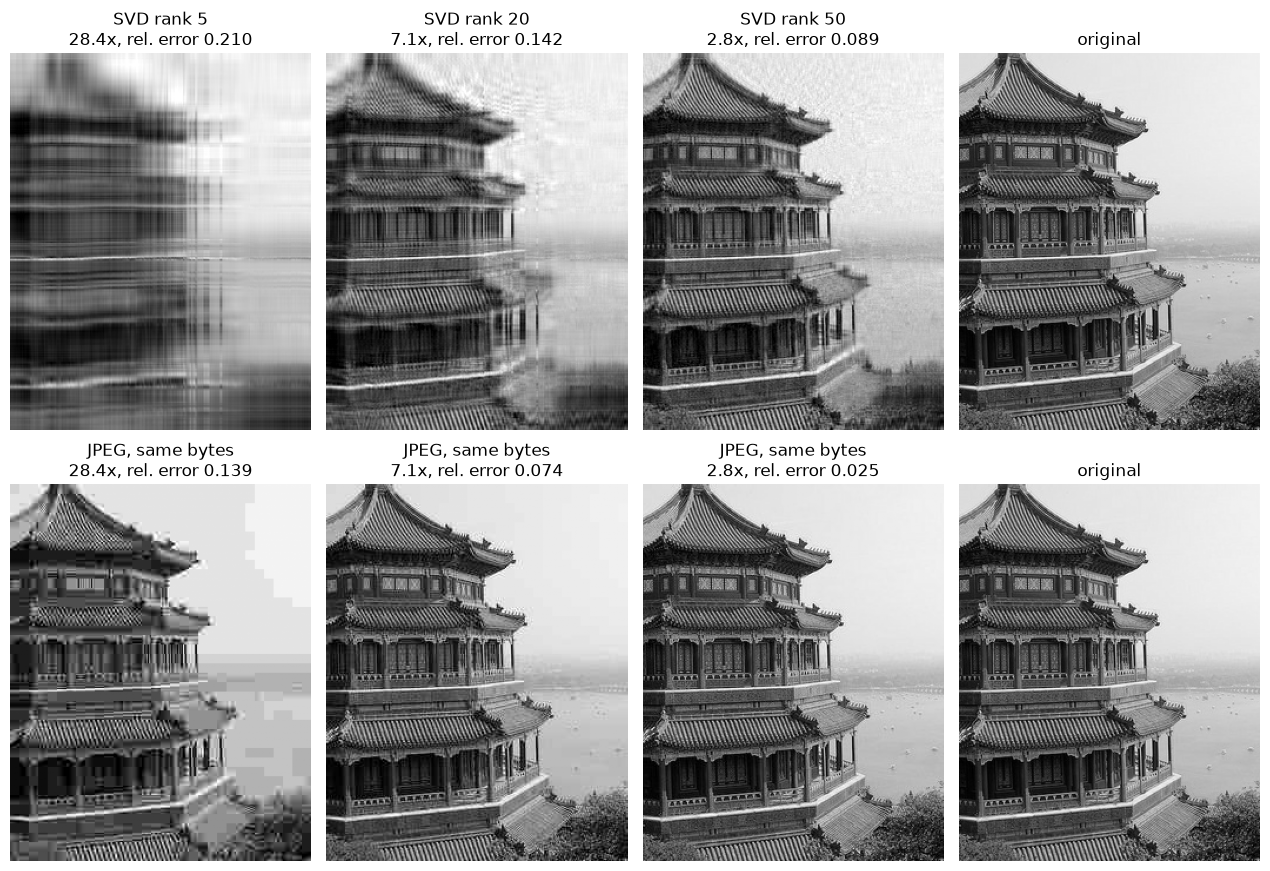

In [39]:
ks_shown = list(A_jpeg)
fig, axes = plt.subplots(2, len(ks_shown) + 1, figsize=(3.2 * (len(ks_shown) + 1), 9.0))
for col, k in enumerate(ks_shown):
    ratio = m * n / (k * (m + n + 1))
    for row, (img, label) in enumerate([(A_k[k], f"SVD rank {k}"), (A_jpeg[k], "JPEG, same bytes")]):
        err = np.linalg.norm(A - img) / np.linalg.norm(A)
        axes[row, col].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{label}\n{ratio:.1f}x, rel. error {err:.3f}")
        axes[row, col].axis("off")
for row in range(2):
    axes[row, -1].imshow(A, cmap="gray", vmin=0, vmax=255)
    axes[row, -1].set_title("original")
    axes[row, -1].axis("off")
plt.tight_layout()
plt.show()

**Discuss (optional):**

- At the same byte budget, which scheme has the lower relative error, and by how much? Does
  your eye agree with the number? Look at *where* each one fails: what do the SVD's errors
  look like, and what do JPEG's look like?
- JPEG could not be given rank 1's budget at all. Why is there a floor on how small a JPEG
  can be?
- Part 5 showed nothing beats the truncated SVD. Why does JPEG beating it here not contradict
  Eckart-Young? (What set of matrices does Eckart-Young optimise over, and is the JPEG frame
  in it?)
- What would you now write in the memo's caveat about the SVD scheme versus an off-the-shelf
  codec?